## imports

In [ ]:
# import os
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
import time
from pathlib import Path
from collections import Counter
import cv2
# from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split    


# path = Path('/kaggle/input/datasets/rihabsabri/brainscan-data/Data')
path = Path('../Data')

## check valide syntax
## and classes balance

In [2]:
valide_extentions = ['.jpeg', '.jpg', '.bmp', '.png']
result = []
classes = []
imgCount_class = {}
# path = Path('../Data')

for folder in path.iterdir():
    if folder.is_dir():
        extensions = Counter(
            file.suffix.lower()
            for file in folder.iterdir()
            if file.is_file()
        )
        files_count = sum(
            1 for file in folder.iterdir() 
            if file.is_file()
        )

    f = {'folder' : folder.name, 'extensions' : extensions}
    result.append(f)
    classes.append(folder.name)
    imgCount_class[folder.name] = files_count


print(imgCount_class)
print(classes)
    

{'pituitary': 1757, 'notumor': 2000, 'meningioma': 1645, 'glioma': 1621}
['pituitary', 'notumor', 'meningioma', 'glioma']


## list&labels

In [3]:
labels = []
images = []
valide_extentions = ['.jpg', '.jpeg', '.bmp', '.png']
# path = Path('../Data')

classes = sorted([folder.name for folder in path.iterdir() if folder.is_dir()])

for label, class_name in enumerate(classes):
    folder = path / class_name
    for file in folder.iterdir():
        if file.suffix.lower() in valide_extentions:
            img = cv2.imread(file)
            if img is None:
                print('image didn t load. it will be skipped!')
                continue

            img = cv2.resize(img, (224, 224))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            images.append(img)
            labels.append(label)

print(len(images))
print(len(labels))

y = np.array(labels)
X = np.array(images)

assert len(y) == len(X), 'mismatsh between images and lables length!'   
# print(enumerate(classes))

7023
7023


In [4]:
# verify data shape
print(X.shape[:])
print(y.shape[:])
X.dtype

(7023, 224, 224, 3)
(7023,)


dtype('uint8')

Text(0, 0.5, 'imgaes count')

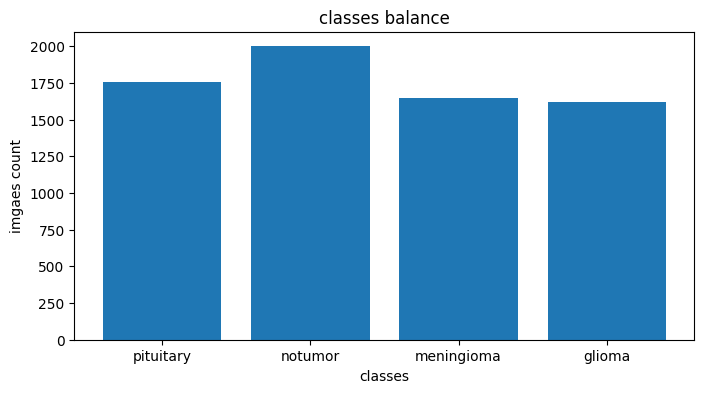

In [5]:
plt.figure(figsize=(8, 4))
plt.bar(imgCount_class.keys(), imgCount_class.values())
plt.title('classes balance')
plt.xlabel('classes')
plt.ylabel('imgaes count')

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2 ,random_state=42)


# split the training set into training/validations sets
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, 
    y_train,
    random_state=42,
    stratify=y_train,
    test_size=0.15
)
print(X_train.shape)
print(X_test.shape)


(5618, 224, 224, 3)
(1405, 224, 224, 3)


## normalisation

In [7]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print(X_train.max())
print(X_test.max())
print(X_train.min())
print(X_test.min())

1.0
1.0
0.0
0.0


In [ ]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu',padding="same"),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu',padding="same"),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu',padding="same"),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(256, (3, 3), activation='relu',padding="same"),
    tf.keras.layers.MaxPooling2D(2, 2),
    # tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(4, activation='softmax')  
])

model.summary()

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
EPOCHS = 20
BATCH_SIZE = 32

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    'best_model.keras',
    monitor = 'val_accuracy',
    save_best_only = True,
    verbose = 1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3
)

start = time.time()

history = model.fit(
    X_train,
    y_train,
    epochs = EPOCHS,
    batch_size = BATCH_SIZE,
    validation_data = (X_val, y_val),
    callbacks = [checkpoint, early_stopping, reduce_lr]
)
end = time.time()

# Accuracy graph
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss graph
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()
print(f'Training time: {end - start:.2f}s')

2026-10-18 18:04:41.724887: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,211,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,600,004 (13.73 MB)

 Trainable params: 3,600,004 (13.73 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4919 - loss: 1.1653
Epoch 1: val_accuracy improved from None to 0.41874, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 402s 2s/step - accuracy: 0.6040 - loss: 0.9522 - val_accuracy: 0.4187 - val_loss: 226.5841 - learning_rate: 0.0010
Epoch 2/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7517 - loss: 0.6101
Epoch 2: val_accuracy did not improve from 0.41874
176/176 ━━━━━━━━━━━━━━━━━━━━ 389s 2s/step - accuracy: 0.7686 - loss: 0.5799 - val_accuracy: 0.3120 - val_loss: 652.7770 - learning_rate: 0.0010
Epoch 3/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8137 - loss: 0.4740
Epoch 3: val_accuracy did not improve from 0.41874
176/176 ━━━━━━━━━━━━━━━━━━━━ 397s 2s/step - accuracy: 0.8247 - loss: 0.4504 - val_accuracy: 0.4116 - val_loss: 656.3801 - learning_rate: 0.0010
Epoch 4/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8481 - l

In [11]:
model.evaluate(
    X_test,
    y_test
)

44/44 ━━━━━━━━━━━━━━━━━━━━ 28s 638ms/step - accuracy: 0.9338 - loss: 0.1892


[0.18922331929206848, 0.9338078498840332]

In [12]:
from sklearn.metrics import classification_report, confusion_matrix

# Get predicted probabilities and convert them to class indices
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# Print detailed per-class metrics
print(classification_report(y_test, y_pred))

# Print confusion matrix
print(confusion_matrix(y_test, y_pred))

44/44 ━━━━━━━━━━━━━━━━━━━━ 28s 641ms/step
              precision    recall  f1-score   support

           0       0.93      0.89      0.91       348
           1       0.84      0.89      0.87       318
           2       0.99      0.96      0.98       395
           3       0.97      0.98      0.98       344

    accuracy                           0.93      1405
   macro avg       0.93      0.93      0.93      1405
weighted avg       0.94      0.93      0.93      1405

[[310  35   0   3]
 [ 23 284   4   7]
 [  1  13 381   0]
 [  1   5   1 337]]


In [13]:
from IPython.display import FileLink
FileLink('best_model.keras')

/kaggle/working/best_model.keras

In [5]:
import cv2
import numpy as np
import tensorflow as tf

# load the saved model
model = tf.keras.models.load_model('../models/best_model.keras')

# must match the sorted order used during training
label_map = {0: 'glioma', 1: 'meningioma', 2: 'notumor', 3: 'pituitary'}

def predict_image(path):
    # load
    img = cv2.imread(path)
    if img is None:
        raise ValueError(f"Could not load image: {path}")

    # same preprocessing as training
    img = cv2.resize(img, (224, 224))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = img.astype('float32') / 255.0

    # add batch dimension: (224,224,3) → (1,224,224,3)
    img = np.expand_dims(img, axis=0)

    # predict
    probs = model.predict(img)               # shape (1, 4)
    class_index = np.argmax(probs, axis=1)[0]
    class_name = label_map[class_index]
    confidence = probs[0][class_index]

    return class_name, confidence

# test it
class_name, confidence = predict_image('../predict_img/img4.jpg')
print(f"Prediction: {class_name} ({confidence:.2%})")


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Prediction: notumor (100.00%)
